In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score  # Or mean_squared_error, r2_score

warnings.filterwarnings('ignore')

In [64]:
df = pd.read_csv('data/train.csv')

In [65]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   battery_power  2000 non-null   int64  
 1   blue           2000 non-null   int64  
 2   clock_speed    2000 non-null   float64
 3   dual_sim       2000 non-null   int64  
 4   fc             2000 non-null   int64  
 5   four_g         2000 non-null   int64  
 6   int_memory     2000 non-null   int64  
 7   m_dep          2000 non-null   float64
 8   mobile_wt      2000 non-null   int64  
 9   n_cores        2000 non-null   int64  
 10  pc             2000 non-null   int64  
 11  px_height      2000 non-null   int64  
 12  px_width       2000 non-null   int64  
 13  ram            2000 non-null   int64  
 14  sc_h           2000 non-null   int64  
 15  sc_w           2000 non-null   int64  
 16  talk_time      2000 non-null   int64  
 17  three_g        2000 non-null   int64  
 18  touch_screen   2000

In [66]:
print(df["price_range"].unique())

[1 2 3 0]


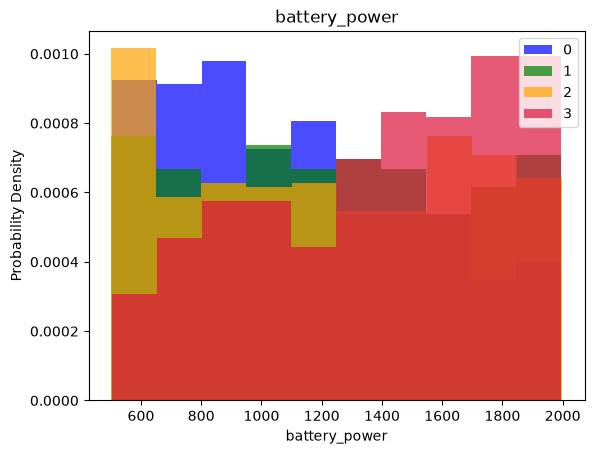

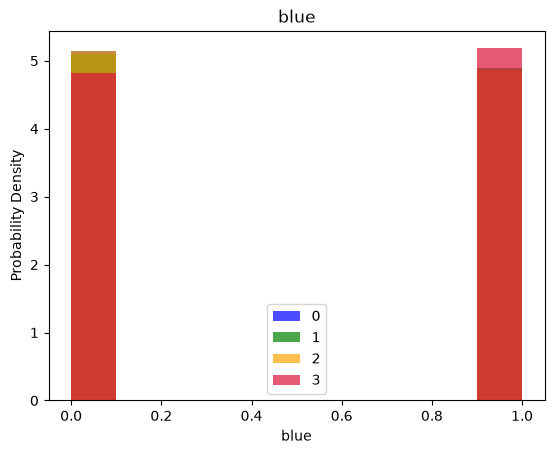

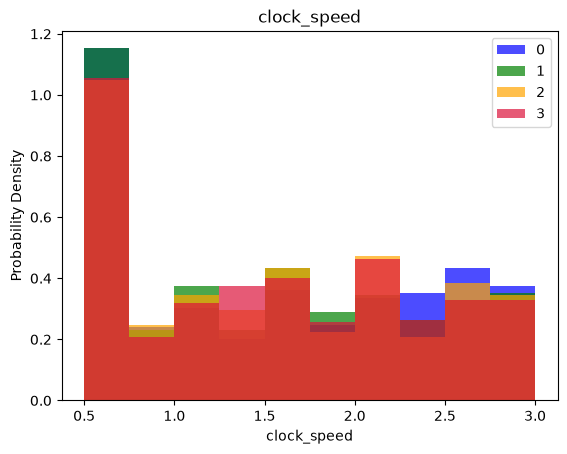

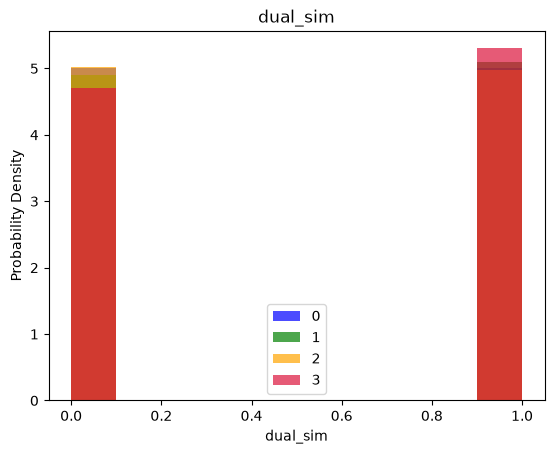

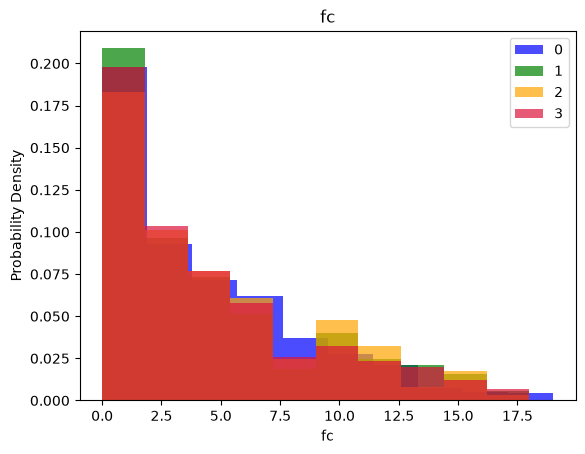

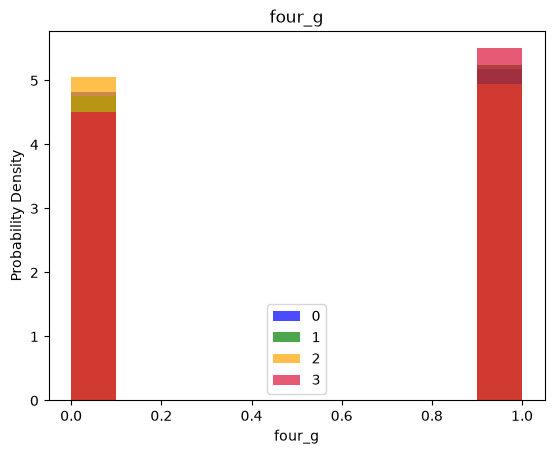

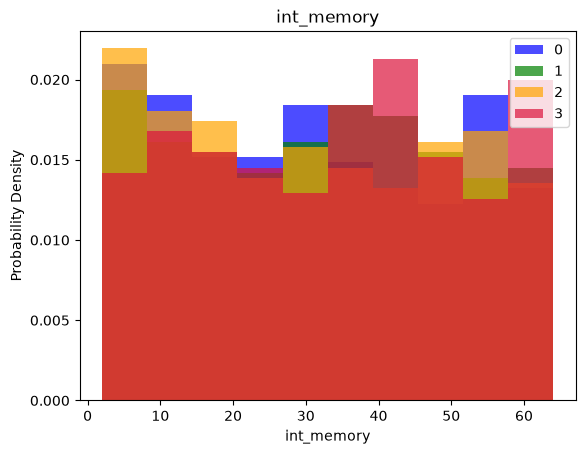

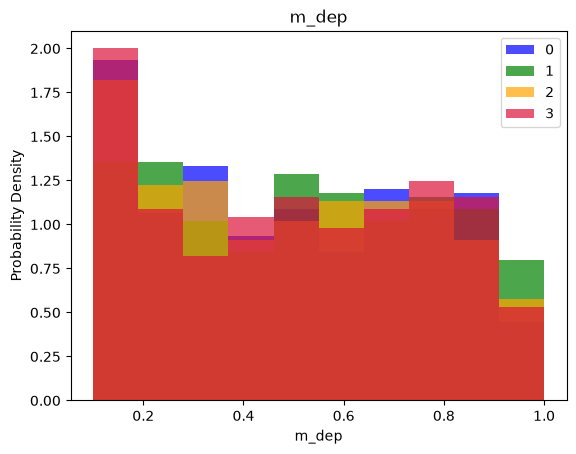

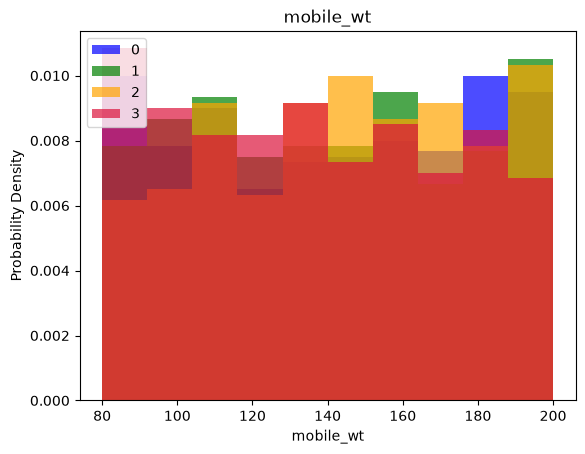

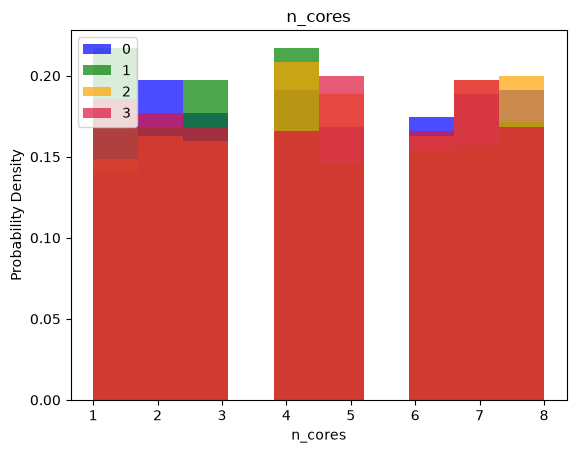

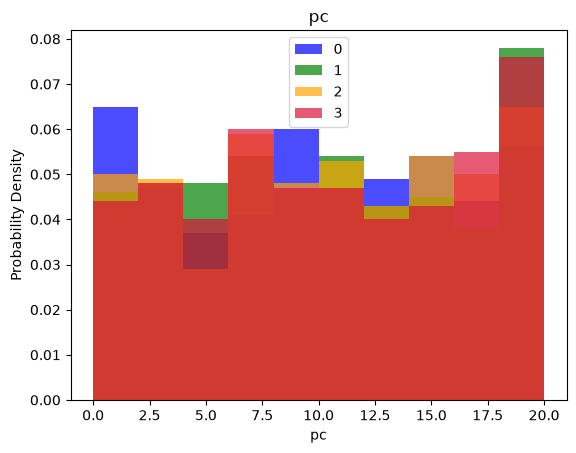

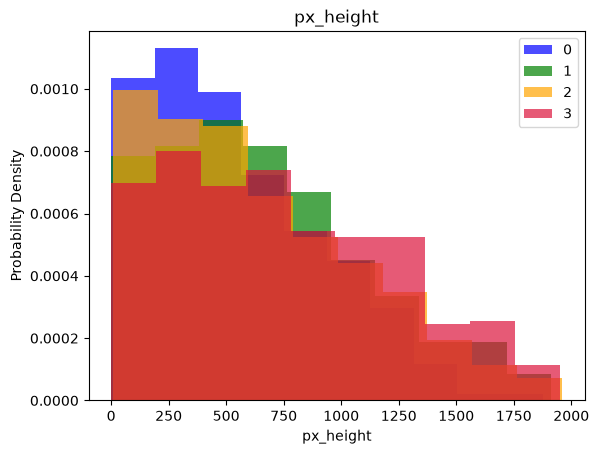

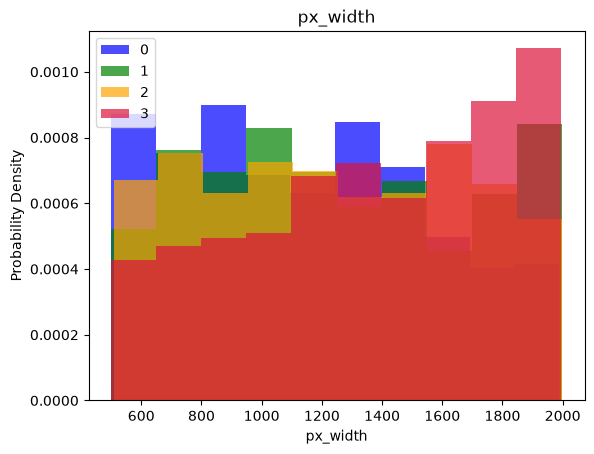

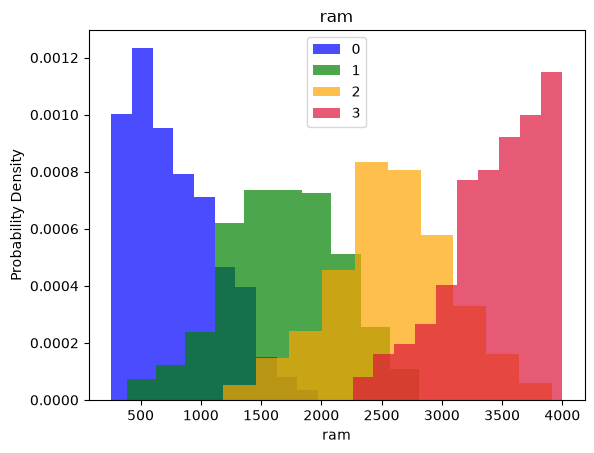

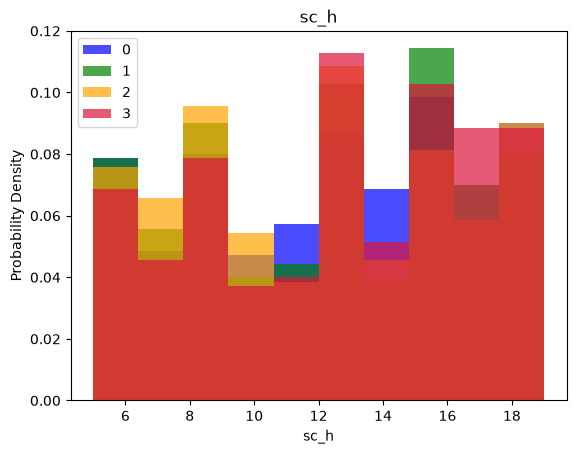

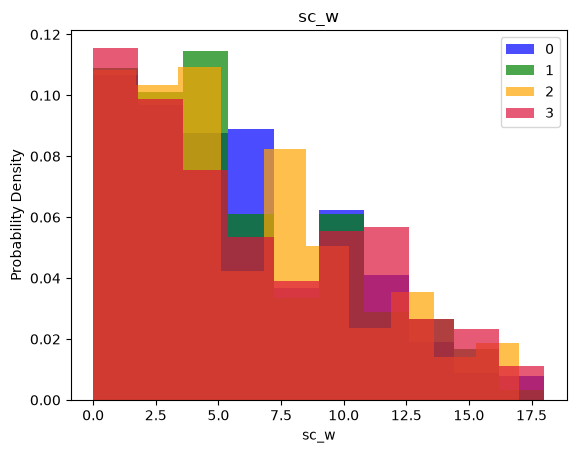

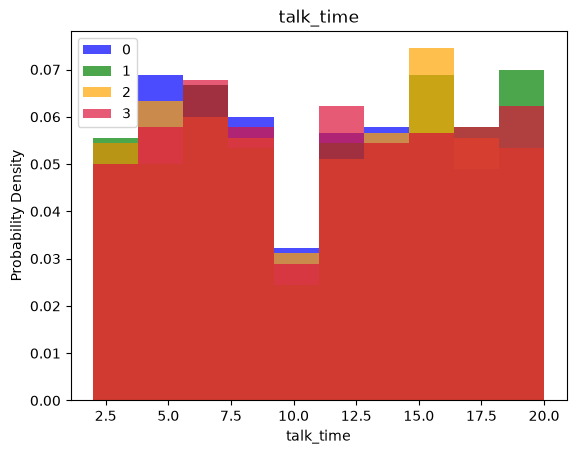

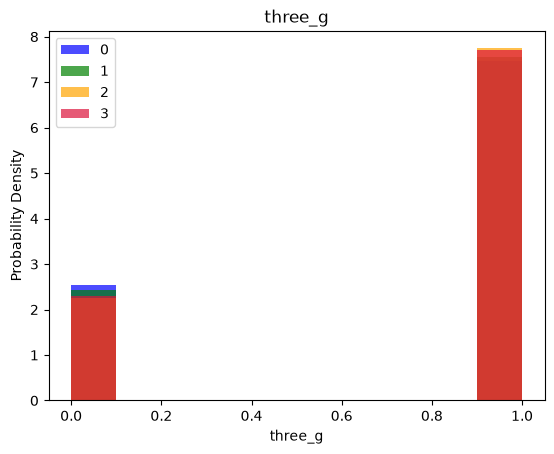

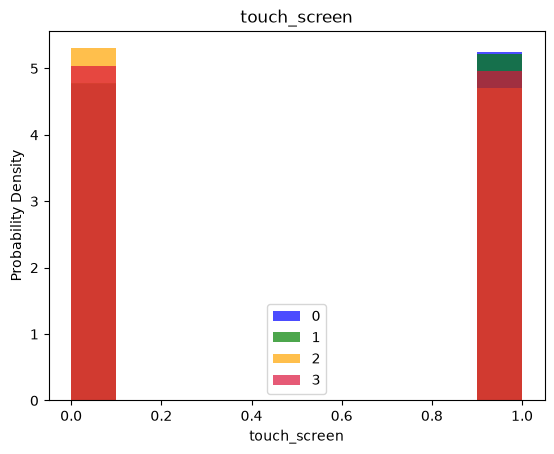

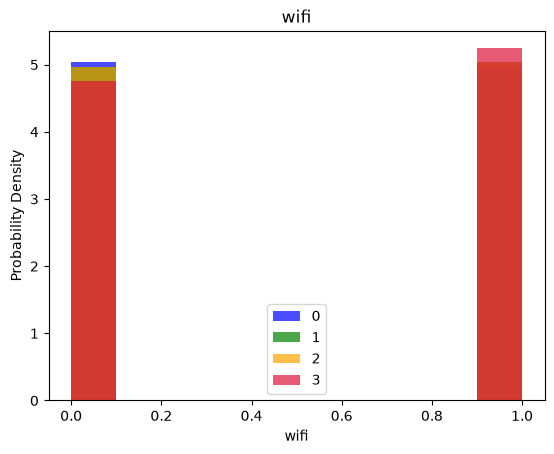

In [67]:
cols = df.columns

for label in cols[:-1]:
  plt.hist(df[df["price_range"]==0][label], color='blue', label='0', alpha=0.7, density=True)
  plt.hist(df[df["price_range"]==1][label], color='green', label='1', alpha=0.7, density=True)
  plt.hist(df[df["price_range"]==2][label], color='orange', label='2', alpha=0.7, density=True)
  plt.hist(df[df["price_range"]==3][label], color='crimson', label='3', alpha=0.7, density=True)
  plt.title(label)
  plt.ylabel("Probability Density")
  plt.xlabel(label)
  plt.legend()
  plt.show()

In [68]:
# 1. Feature / Target separation
X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values

# 2. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

# 3. Model Initialization
rf_model = RandomForestClassifier(
    n_estimators=100,      # Number of decision trees
    max_depth=None,        # Maximum depth of each tree
    min_samples_split=2,   # Minimum samples required to split an internal node
    min_samples_leaf=1,    # Minimum samples required at a leaf node
    random_state=42,
    n_jobs=-1              # Use all available CPU cores
)

In [69]:
rf_model.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [74]:
feature_names = df.columns[:-1]
importances = rf_model.feature_importances_
feature_imp_df = pd.DataFrame({'Feature': feature_names, 'Gini Importance': importances}).sort_values(
    'Gini Importance', ascending=False)
print(feature_imp_df)

feature_imp_df.to_csv('feature_importance.csv', index=False)

          Feature  Gini Importance
13            ram         0.458098
0   battery_power         0.073734
12       px_width         0.059472
11      px_height         0.057745
6      int_memory         0.040384
8       mobile_wt         0.040155
10             pc         0.031049
16      talk_time         0.030855
2     clock_speed         0.030386
15           sc_w         0.029968
14           sc_h         0.029481
4              fc         0.027306
7           m_dep         0.024602
9         n_cores         0.023988
3        dual_sim         0.007676
19           wifi         0.007420
1            blue         0.007279
18   touch_screen         0.007040
5          four_g         0.006971
17        three_g         0.006391


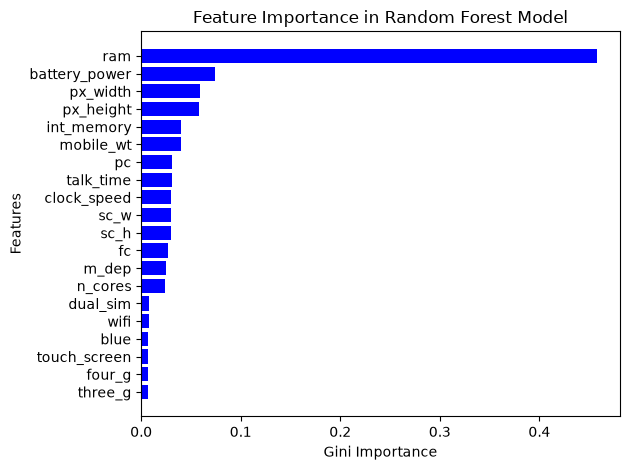

In [ ]:
sorted_df = feature_imp_df.sort_values(by='Gini Importance', ascending=True)

y = sorted_df['Feature']
x = sorted_df['Gini Importance']

plt.barh(y, x, color='blue')

plt.xlabel('Gini Importance')
plt.ylabel('Features')
plt.title('Feature Importance in Random Forest Model')

plt.tight_layout()

plt.show()

In [ ]:
y = feature_imp_df['Feature']
x = feature_imp_df['Gini Importance'].sort_values(ascending=True)

plt.barh(y, x, color='blue')

plt.xlabel('Gini Importance')
plt.ylabel('Features')
plt.title('Feature Importance in Random Forest Model')

plt.show()

in given graph, the ranking is unsorted, and ram got the highest score

In [72]:
y_pred = rf_model.predict(X_test)

In [73]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.8666666666666667

Classification Report:
               precision    recall  f1-score   support

           0       0.94      0.95      0.94       151
           1       0.82      0.82      0.82       146
           2       0.79      0.78      0.79       148
           3       0.92      0.91      0.92       155

    accuracy                           0.87       600
   macro avg       0.87      0.87      0.87       600
weighted avg       0.87      0.87      0.87       600

